# 01 — Exploratory data analysis: NIH ChestX-ray14

**Scope: training and validation images only.** The NIH test set (`test_list.txt`)
is quarantined until the final evaluation and is removed in the first code cell.
Nothing below is computed on it.

Figures are written to `docs/figures/eda/` for use in the dissertation. The
findings and what they imply for the model are collected in
`docs/eda-summary.md`.

| § | Question |
|---|---|
| 1 | How big is the data, and is the patient-level split clean? |
| 2 | How common is each finding? |
| 3 | How many findings does one image carry? |
| 4 | Which findings occur together? |
| 5 | How many images does each patient contribute? |
| 6 | Who are the patients (age, sex)? |
| 7 | How were the images taken (PA vs AP view)? |
| 8 | What do the image files look like (size, pixel spacing, format)? |
| 9 | What do the radiographs look like? |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "ml" / "src" / "lecad").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "ml" / "src"))

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from lecad.config import PATHS
from lecad.image_index import resolve
from lecad.labels import LABELS, NO_FINDING
from lecad.splits import load_split_frame

FIG = ROOT / "docs" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# One visual system for every figure: two categorical slots, one blue ramp,
# recessive axes. Print target, so a white surface.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUES = mpl.colors.LinearSegmentedColormap.from_list(
    "lecad_blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])

mpl.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK2, "legend.frameon": False, "figure.dpi": 110,
    "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "white",
})
pd.set_option("display.precision", 2)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()


# ---- Load, then drop the test set before anything else happens. ----
df = load_split_frame()
df = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
assert set(df["split"]) == {"train", "val"}, "test rows must not be present"

L = list(LABELS)
print(f"data root: {PATHS.data_root}")
print(f"rows loaded (train + val only): {len(df):,}")

data root: D:\Work\archive
rows loaded (train + val only): 86,524


## 1. Size of the data and integrity of the split

In [2]:
overview = df.groupby("split").agg(images=("Image Index", "size"),
                                   patients=("Patient ID", "nunique"))
overview.loc["train + val"] = [len(df), df["Patient ID"].nunique()]
overview["images per patient"] = overview["images"] / overview["patients"]
overview["share of images"] = overview["images"] / len(df) * 100

train_p = set(df.loc[df.split == "train", "Patient ID"])
val_p = set(df.loc[df.split == "val", "Patient ID"])
print(f"patients in both train and val: {len(train_p & val_p)}")
print(f"duplicate image filenames: {df['Image Index'].duplicated().sum()}")
overview

patients in both train and val: 0
duplicate image filenames: 0


,images,patients,images per patient,share of images
split,,,,
train,73499,23807,3.09,84.95
val,13025,4201,3.10,15.05
train + val,86524,28008,3.09,100.00


## 2. How common is each finding?

Labels were mined from radiology reports by NLP, not drawn on the images. "No Finding"
means none of the 14 patterns was reported. It does not mean the radiograph is normal.

In [3]:
prev = pd.DataFrame({
    "images": df[L].sum(),
    "% of train+val": df[L].mean() * 100,
    "% of train": df.loc[df.split == "train", L].mean() * 100,
    "% of val": df.loc[df.split == "val", L].mean() * 100,
}).sort_values("images", ascending=False)
prev["images"] = prev["images"].astype(int)
prev["imbalance (neg:pos)"] = ((len(df) - prev["images"]) / prev["images"]).round(0).astype(int)

no_finding = (df["Finding Labels"] == NO_FINDING).mean() * 100
print(f"'No Finding': {no_finding:.1f}% of train+val images")
prev.to_csv(FIG / "label_prevalence.csv")
prev

'No Finding': 58.4% of train+val images


,images,% of train+val,% of train,% of val,imbalance (neg:pos)
Infiltration,13782,15.93,15.82,16.55,5
Effusion,8659,10.01,9.85,10.91,9
Atelectasis,8280,9.57,9.46,10.20,9
Nodule,4708,5.44,5.38,5.80,17
Mass,4034,4.66,4.69,4.51,20
Consolidation,2852,3.30,3.27,3.46,29
Pneumothorax,2637,3.05,3.02,3.20,32
Pleural_Thickening,2242,2.59,2.57,2.73,38
Cardiomegaly,1707,1.97,1.95,2.10,50
Emphysema,1423,1.64,1.59,1.93,60


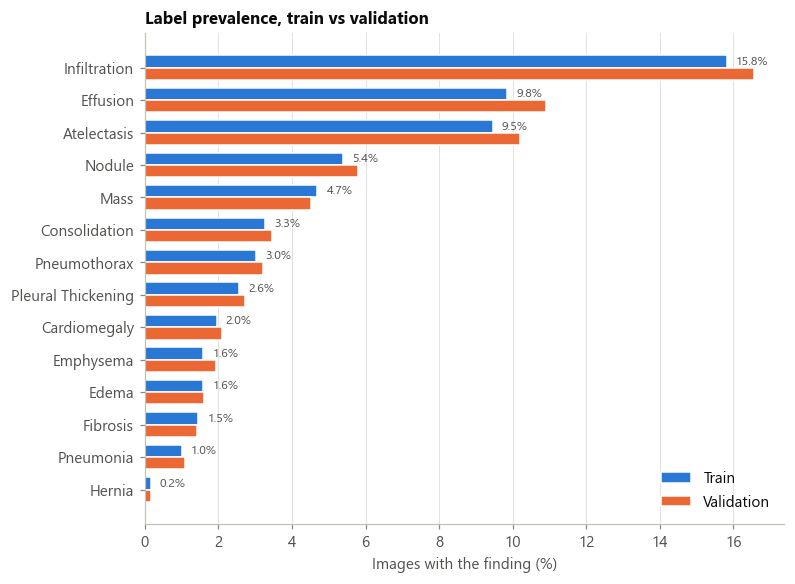

In [4]:
order = prev.index[::-1]
y = np.arange(len(order))
h = 0.38
fig, ax = plt.subplots(figsize=(7.5, 5.8))
ax.barh(y + h / 2, prev.loc[order, "% of train"], height=h, color=BLUE, label="Train",
        edgecolor="white", linewidth=1)
ax.barh(y - h / 2, prev.loc[order, "% of val"], height=h, color=ORANGE, label="Validation",
        edgecolor="white", linewidth=1)
for yi, name in zip(y, order, strict=True):
    pct = prev.loc[name, "% of train"]
    ax.text(pct + 0.25, yi + h / 2, f"{pct:.1f}%", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, [n.replace("_", " ") for n in order])
ax.set_xlabel("Images with the finding (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Label prevalence, train vs validation")
ax.legend(loc="lower right")
save(fig, "01_label_prevalence")

## 3. How many findings does one image carry?

images with >= 1 finding: 36,024 (41.6%)
mean findings per positive image: 1.50
positive images with >= 2 findings: 36.2%


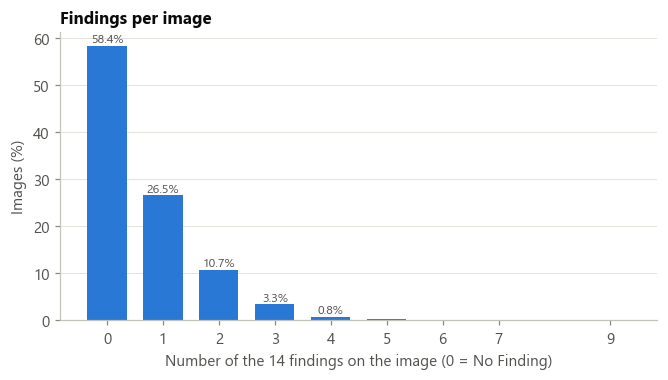

,images,%
0,50500,5.84e+01
1,22971,2.65e+01
2,9285,1.07e+01
3,2898,3.35e+00
4,675,7.80e-01
5,149,1.72e-01
6,36,4.16e-02
7,8,9.25e-03
9,2,2.31e-03


In [5]:
n_labels = df[L].sum(axis=1)
dist = n_labels.value_counts().sort_index()
dist_pct = dist / len(df) * 100
positive = n_labels[n_labels > 0]
print(f"images with >= 1 finding: {len(positive):,} ({len(positive) / len(df) * 100:.1f}%)")
print(f"mean findings per positive image: {positive.mean():.2f}")
print(f"positive images with >= 2 findings: {(positive >= 2).mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(dist.index, dist_pct, color=BLUE, width=0.7)
for k, v in dist_pct.items():
    if v >= 0.5:
        ax.text(k, v + 0.8, f"{v:.1f}%", ha="center", fontsize=8, color=INK2)
ax.set_xticks(dist.index)
ax.set_xlabel("Number of the 14 findings on the image (0 = No Finding)")
ax.set_ylabel("Images (%)")
ax.grid(axis="x", visible=False)
ax.set_title("Findings per image")
save(fig, "02_findings_per_image")
pd.DataFrame({"images": dist, "%": dist_pct})

## 4. Which findings occur together?

Cell (row A, column B) = P(B | A): among images labelled A, the share also labelled B.
The matrix is not symmetric. Strong co-occurrence matters for two reasons. The model can
learn one finding as a proxy for another. Grad-CAM for one label may light up evidence
for its companion.

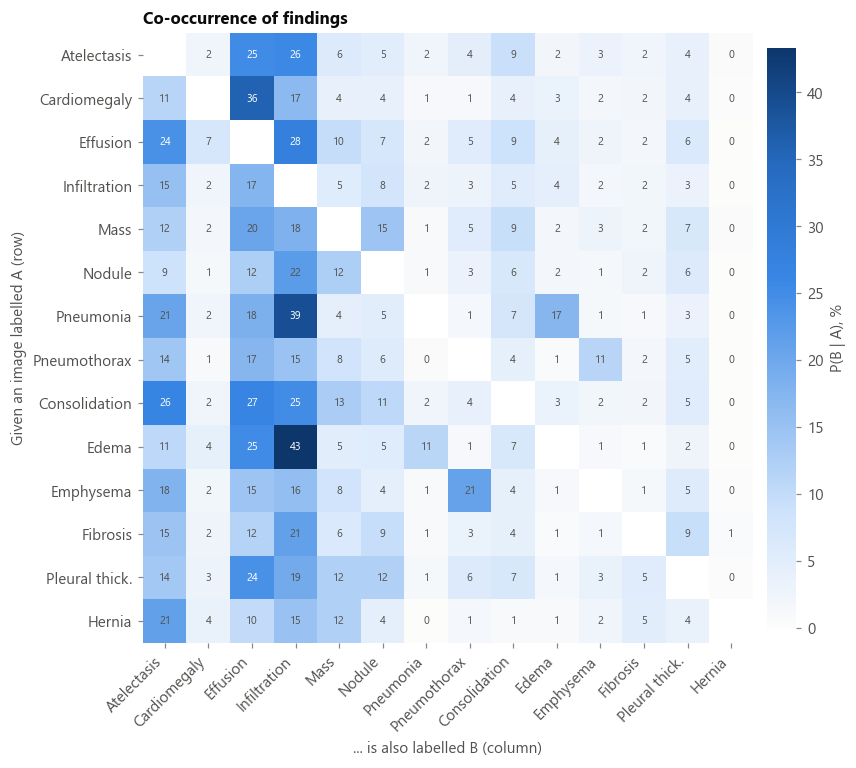

,finding A,finding B,images with both
0,Effusion,Infiltration,2404
1,Atelectasis,Infiltration,2119
2,Atelectasis,Effusion,2086
3,Infiltration,Nodule,1036
4,Effusion,Mass,824
5,Effusion,Consolidation,761
6,Atelectasis,Consolidation,755
7,Infiltration,Mass,737
8,Infiltration,Consolidation,712
9,Cardiomegaly,Effusion,611


,% of its images where it is the only finding
Pneumonia,26.71
Edema,28.81
Consolidation,29.07
Effusion,32.20
Pleural_Thickening,36.44
Atelectasis,41.23
Emphysema,41.25
Mass,42.04
Fibrosis,44.04
Cardiomegaly,45.52


In [6]:
X = df[L].to_numpy(dtype=np.int64)
co = X.T @ X
cond = co / np.diag(co)[:, None] * 100
np.fill_diagonal(cond, np.nan)

alone = pd.Series(
    {lab: ((df[lab] == 1) & (n_labels == 1)).sum() / df[lab].sum() * 100 for lab in L},
    name="% of its images where it is the only finding",
).sort_values()

short = [n.replace("_", " ").replace("Pleural Thickening", "Pleural thick.") for n in L]
fig, ax = plt.subplots(figsize=(8.5, 7.2))
im = ax.imshow(cond, cmap=BLUES, vmin=0, vmax=np.nanmax(cond))
for i in range(len(L)):
    for j in range(len(L)):
        if i != j:
            v = cond[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanmax(cond) * 0.55 else INK2)
ax.set_xticks(range(len(L)), short, rotation=45, ha="right")
ax.set_yticks(range(len(L)), short)
ax.set_xlabel("... is also labelled B (column)")
ax.set_ylabel("Given an image labelled A (row)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("P(B | A), %", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Co-occurrence of findings")
save(fig, "03_cooccurrence")

pairs = [(L[i], L[j], int(co[i, j])) for i in range(len(L)) for j in range(i + 1, len(L))]
top_pairs = pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:10],
                         columns=["finding A", "finding B", "images with both"])
display(top_pairs)
alone.to_frame()

## 5. How many images does each patient contribute?

This is why validation is split by patient. Many patients have long series of follow-up
films. An image-level split would put the same person on both sides.

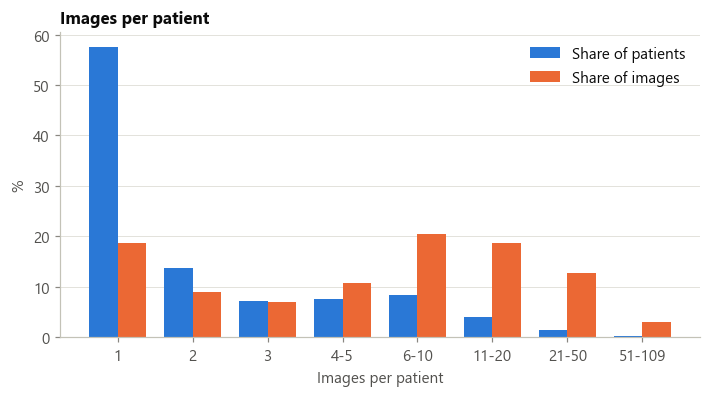

,value
patients,28008.00
with exactly 1 image (%),57.59
median images / patient,1.00
mean images / patient,3.09
max images / patient,109.00
patients with >= 10 images (%),6.62
share of images from those patients (%),37.60


In [7]:
per_patient = df.groupby("Patient ID").size()
summary = pd.Series({
    "patients": len(per_patient),
    "with exactly 1 image (%)": (per_patient == 1).mean() * 100,
    "median images / patient": per_patient.median(),
    "mean images / patient": per_patient.mean(),
    "max images / patient": per_patient.max(),
    "patients with >= 10 images (%)": (per_patient >= 10).mean() * 100,
    "share of images from those patients (%)":
        per_patient[per_patient >= 10].sum() / len(df) * 100,
}).round(2)

bins = [1, 2, 3, 4, 6, 11, 21, 51, per_patient.max() + 1]
labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21-50", f"51-{per_patient.max()}"]
grouped = pd.cut(per_patient, bins=bins, right=False, labels=labels)
pat_share = grouped.value_counts(sort=False) / len(per_patient) * 100
img_share = per_patient.groupby(grouped, observed=False).sum() / len(df) * 100

x = np.arange(len(labels))
w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(x - w / 2, pat_share, w, color=BLUE, label="Share of patients")
ax.bar(x + w / 2, img_share, w, color=ORANGE, label="Share of images")
ax.set_xticks(x, labels)
ax.set_xlabel("Images per patient")
ax.set_ylabel("%")
ax.grid(axis="x", visible=False)
ax.legend()
ax.set_title("Images per patient")
save(fig, "04_images_per_patient")
summary.to_frame("value")

## 6. Who are the patients? Age and sex

implausible ages (> 100) set to missing: 12 (max recorded: 413)
age: median 49, IQR 35-59
images from patients under 18: 4,190 (4.8%)
sex (images): M 48,458 (56.0%), F 38,066 (44.0%)


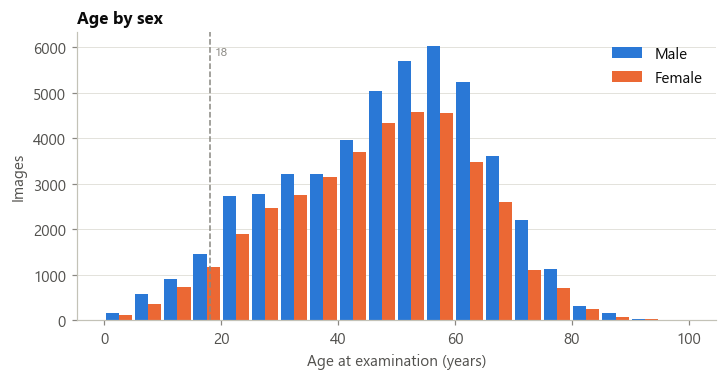

Patient Gender,% female,% male,female : male ratio,median age
Emphysema,1.38,1.85,0.74,57.0
Mass,4.13,5.08,0.81,51.0
Pleural_Thickening,2.31,2.81,0.82,54.0
Atelectasis,8.64,10.30,0.84,53.0
Nodule,5.13,5.68,0.90,52.0
Pneumonia,0.98,1.04,0.94,47.0
Consolidation,3.22,3.36,0.96,48.0
Infiltration,15.74,16.08,0.98,48.0
Effusion,10.41,9.69,1.07,52.0
Fibrosis,1.54,1.37,1.13,54.0


In [8]:
raw_age = pd.read_csv(PATHS.metadata_csv, usecols=["Image Index", "Patient Age"])
raw_age = raw_age[raw_age["Image Index"].isin(df["Image Index"])]
print(f"implausible ages (> 100) set to missing: {(raw_age['Patient Age'] > 100).sum()} "
      f"(max recorded: {raw_age['Patient Age'].max()})")

age = df["Patient Age"]
under18 = (age < 18).sum()
print(f"age: median {age.median():.0f}, IQR {age.quantile(.25):.0f}-{age.quantile(.75):.0f}")
print(f"images from patients under 18: {under18:,} ({under18 / len(df) * 100:.1f}%)")

sex = df["Patient Gender"].value_counts()
print("sex (images):",
      ", ".join(f"{k} {v:,} ({v / len(df) * 100:.1f}%)" for k, v in sex.items()))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
edges = np.arange(0, 101, 5)
ax.hist([age[df["Patient Gender"] == "M"].dropna(), age[df["Patient Gender"] == "F"].dropna()],
        bins=edges, color=[BLUE, ORANGE], label=["Male", "Female"], rwidth=0.9)
ax.axvline(18, color=MUTED, linewidth=1, linestyle="--")
ax.text(18.8, ax.get_ylim()[1] * 0.92, "18", color=MUTED, fontsize=8)
ax.set_xlabel("Age at examination (years)")
ax.set_ylabel("Images")
ax.grid(axis="x", visible=False)
ax.legend()
ax.set_title("Age by sex")
save(fig, "05_age_sex")

by_sex = (df.groupby("Patient Gender")[L].mean().T * 100).rename(
    columns={"M": "% male", "F": "% female"})
by_sex["female : male ratio"] = by_sex["% female"] / by_sex["% male"]
by_sex["median age"] = [df.loc[df[lab] == 1, "Patient Age"].median() for lab in L]
by_sex.sort_values("female : male ratio")

## 7. How were the images taken? PA vs AP view

PA (posteroanterior) films are usually taken standing, in outpatients. AP (anteroposterior)
films are often bedside films of sicker, inpatient or supine patients. If prevalence differs
sharply by view, the model can learn **"AP view → disease"** as a shortcut instead of reading
the pathology.

views: PA 56,214 (65.0%), AP 30,310 (35.0%)
'No Finding' by view: AP 52.8%, PA 61.4%


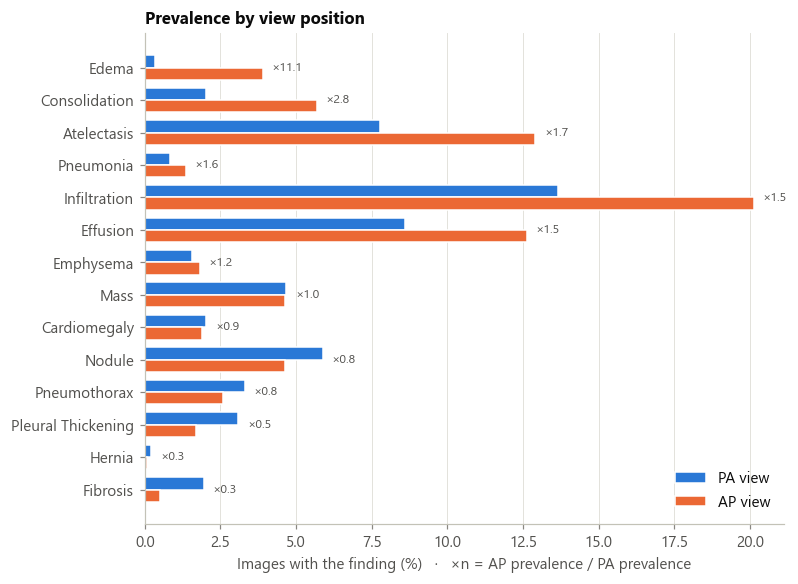

View Position,% in AP,% in PA,AP : PA ratio
Fibrosis,0.51,1.95,0.26
Hernia,0.07,0.22,0.31
Pleural_Thickening,1.68,3.08,0.55
Pneumothorax,2.58,3.30,0.78
Nodule,4.63,5.88,0.79
Cardiomegaly,1.88,2.02,0.93
Mass,4.65,4.67,0.99
Emphysema,1.81,1.55,1.16
Effusion,12.62,8.60,1.47
Infiltration,20.13,13.66,1.47


In [9]:
views = df["View Position"].value_counts()
print("views:", ", ".join(f"{k} {v:,} ({v / len(df) * 100:.1f}%)" for k, v in views.items()))

by_view = (df.groupby("View Position")[L].mean().T * 100).rename(
    columns={"PA": "% in PA", "AP": "% in AP"})
by_view["AP : PA ratio"] = by_view["% in AP"] / by_view["% in PA"]
by_view = by_view.sort_values("AP : PA ratio")
nf_view = df.groupby("View Position")["Finding Labels"].apply(
    lambda s: (s == NO_FINDING).mean() * 100)
print("'No Finding' by view:", ", ".join(f"{k} {v:.1f}%" for k, v in nf_view.items()))

order = by_view.index
y = np.arange(len(order))
h = 0.38
fig, ax = plt.subplots(figsize=(7.5, 5.8))
ax.barh(y + h / 2, by_view.loc[order, "% in PA"], h, color=BLUE, label="PA view",
        edgecolor="white", linewidth=1)
ax.barh(y - h / 2, by_view.loc[order, "% in AP"], h, color=ORANGE, label="AP view",
        edgecolor="white", linewidth=1)
for yi, name in zip(y, order, strict=True):
    r = by_view.loc[name, "AP : PA ratio"]
    x_end = max(by_view.loc[name, "% in PA"], by_view.loc[name, "% in AP"])
    ax.text(x_end + 0.3, yi, f"×{r:.1f}", va="center", fontsize=8, color=INK2)  # noqa: RUF001
ax.set_yticks(y, [n.replace("_", " ") for n in order])
ax.set_xlabel("Images with the finding (%)   ·   ×n = AP prevalence / PA prevalence")  # noqa: RUF001
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Prevalence by view position")
save(fig, "06_prevalence_by_view")
by_view

## 8. What do the image files look like?

In [10]:
meta = pd.read_csv(PATHS.metadata_csv)
meta.columns = [c.strip() for c in meta.columns]
meta = meta[meta["Image Index"].isin(df["Image Index"])]
meta = meta.rename(columns={"OriginalImage[Width": "orig_width", "Height]": "orig_height",
                            "OriginalImagePixelSpacing[x": "spacing_x", "y]": "spacing_y"})
meta[["orig_width", "orig_height", "spacing_x", "spacing_y"]].describe().T

,count,mean,std,min,25%,50%,75%,max
orig_width,86524.0,2641.78,337.14,1143.00,2500.00,2520.00,2992.00,3550.0
orig_height,86524.0,2505.11,403.96,966.00,2048.00,2544.00,2991.00,3166.0
spacing_x,86524.0,0.16,0.02,0.12,0.14,0.14,0.17,0.2
spacing_y,86524.0,0.16,0.02,0.12,0.14,0.14,0.17,0.2


In [11]:
# Open a random sample of the actual files: format, size and brightness.
rng = np.random.default_rng(42)
sample = df.sample(400, random_state=42)
rows = []
for name in sample["Image Index"]:
    with Image.open(resolve(name)) as img:
        arr = np.asarray(img.convert("L"), dtype=np.float32)
        rows.append({"mode": img.mode, "size": f"{img.width}x{img.height}",
                     "mean": arr.mean(), "std": arr.std(),
                     "% black (0)": (arr == 0).mean() * 100})
files = pd.DataFrame(rows)
print("modes:", files["mode"].value_counts().to_dict())
print("sizes:", files["size"].value_counts().to_dict())
files[["mean", "std", "% black (0)"]].describe().T

modes: {'L': 397, 'RGBA': 3}
sizes: {'1024x1024': 400}


,count,mean,std,min,25%,50%,75%,max
mean,400.0,130.29,22.96,70.66,113.23,125.79,149.21,194.26
std,400.0,58.38,10.79,29.34,50.30,60.43,66.68,79.72
% black (0),400.0,2.47,3.71,0.00,0.10,1.11,3.56,32.68


## 9. What do the radiographs look like?

One random training image per finding, choosing images where that finding is the
**only** label, plus one "No Finding" image. This is for visual familiarity. Look for
burned-in text, markers, tubes and lines, and rotated or inverted films. Things like
these can become shortcuts too.

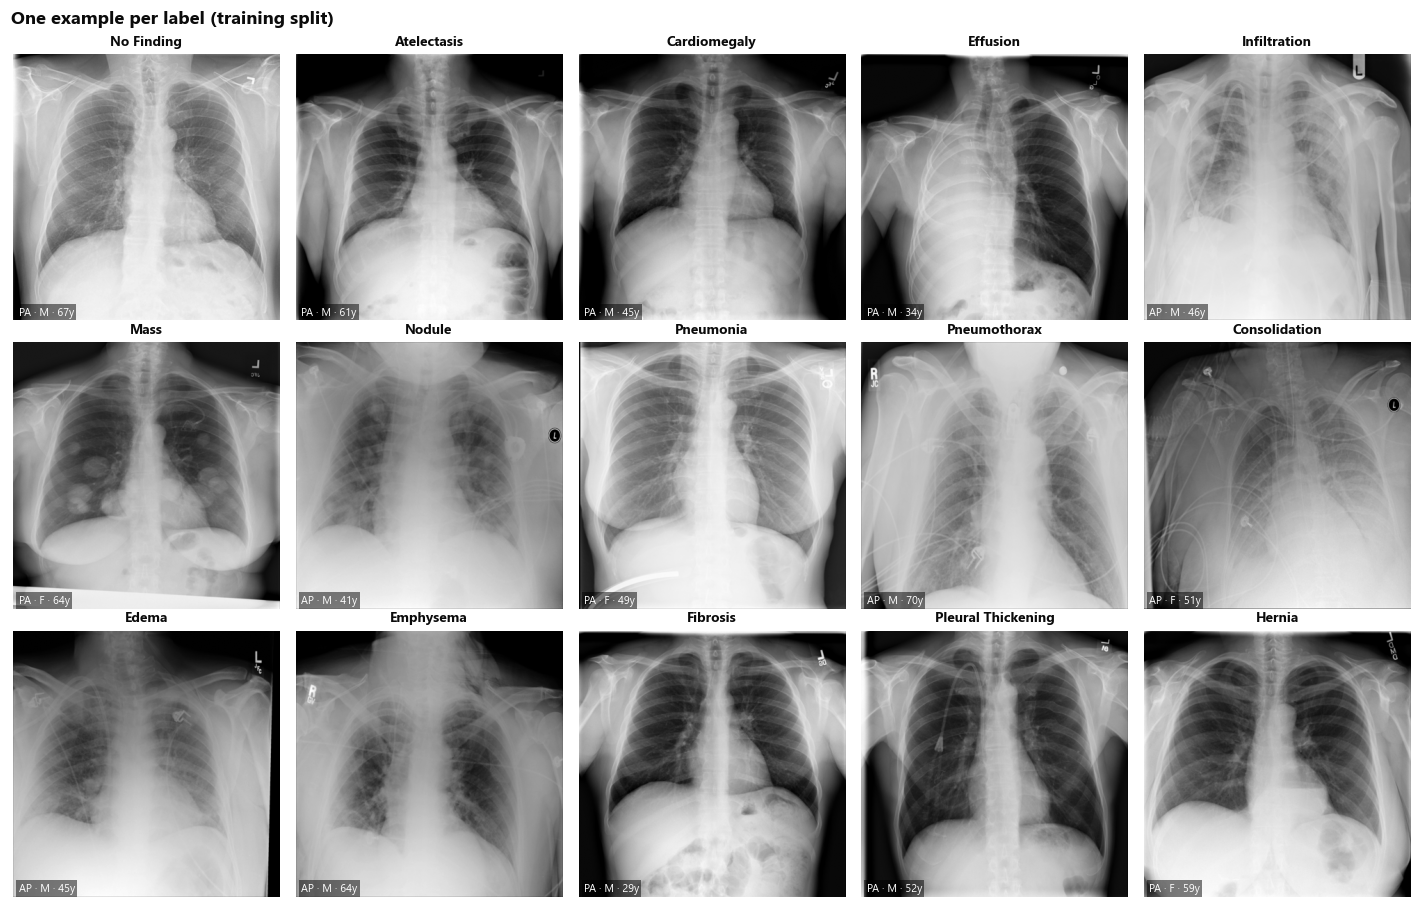

In [12]:
train = df[df.split == "train"]
picks = [(NO_FINDING, train[train["Finding Labels"] == NO_FINDING].sample(1, random_state=7))]
for lab in L:
    only = train[(train[lab] == 1) & (n_labels.loc[train.index] == 1)]
    pool = only if len(only) else train[train[lab] == 1]
    picks.append((lab, pool.sample(1, random_state=7)))

fig, axes = plt.subplots(3, 5, figsize=(13, 8.4))
for ax, (lab, row) in zip(axes.flat, picks, strict=True):
    r = row.iloc[0]
    with Image.open(resolve(r["Image Index"])) as img:
        ax.imshow(img.convert("L").resize((384, 384)), cmap="gray")
    ax.set_title(lab.replace("_", " "), fontsize=9, loc="center")
    caption = f"{r['View Position']} · {r['Patient Gender']} · {r['Patient Age']:.0f}y"
    ax.text(0.02, 0.02, caption, transform=ax.transAxes, color="white", fontsize=7,
            bbox={"facecolor": "black", "alpha": 0.5, "pad": 1.5, "linewidth": 0})
    ax.axis("off")
fig.suptitle("One example per label (training split)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "07_examples_per_label")

## Summary

Full write-up with tables and implications: `docs/eda-summary.md`.

- **Split is clean.** 0 patients shared between train and validation, and label prevalence is matched within 1.1 points.
- **Severe imbalance.** 58.4% "No Finding". Hernia has 141 images (613 negatives per positive). The pos_weight cap of 50 binds for 5 classes.
- **Multi-label.** 1.50 findings per positive image, and 36% of positive images have two or more. Strong co-occurrence: Edema→Infiltration 43%, Pneumonia→Infiltration 39%.
- **Repeat imaging.** 6.6% of patients contribute 37.6% of images, which justifies the patient-level split.
- **Paediatric images.** 4.8% are from patients under 18, which the model card puts out of scope. Decision: retained, with an adults-only result reported alongside.
- **View-position shortcut risk.** Edema is 11× more prevalent on AP films, Consolidation 2.8×. Validation AUC should be reported per view.
- **Visual shortcuts.** Most films have burned-in laterality markers. AP films often show ECG leads and lines. Check Grad-CAM for attention on these.